<a href="https://colab.research.google.com/github/meralbaki/scientific-computing-python/blob/main/thermodynamic_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

THERMODYNAMIC PROPERTY ANALYSIS
Pressure: 5.00 MPa
-----------------------------------------------------------------
Temperature (K)     Density (kg/m3)     Cp (J/kg.K)         
300.00              998.745             4167.029            
325.00              989.313             4170.847            
350.00              975.900             4183.913            
375.00              959.307             4206.627            
400.00              939.910             4242.962            
425.00              917.831             4297.399            
450.00              892.987             4375.474            
475.00              865.078             4485.645            
500.00              833.512             4642.889            


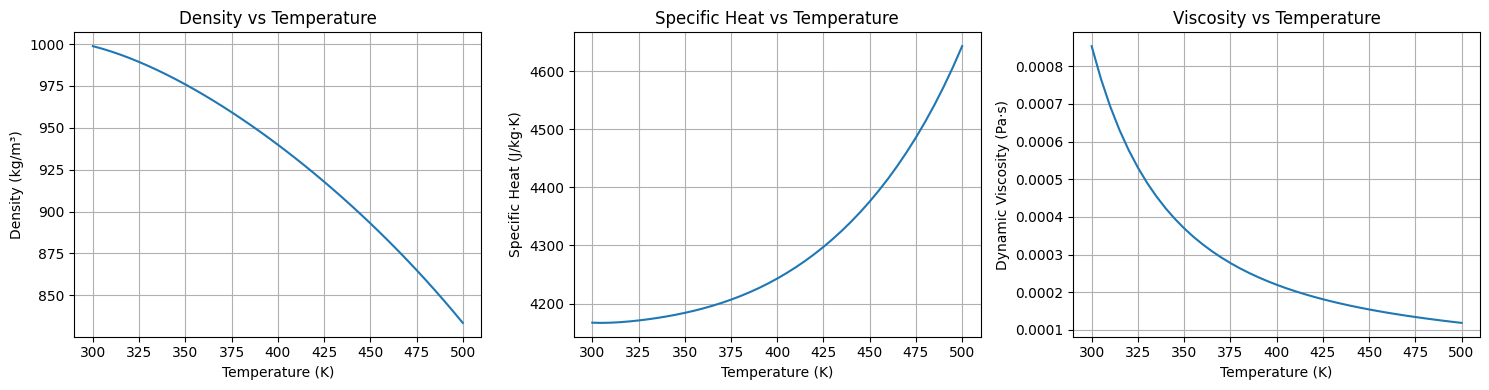

In [4]:
"""
Thermodynamic Property Analysis of Water
Author: Meral Baki
Purpose: Investigate the effect of temperature on
thermophysical properties of water at constant pressure.
"""
!pip install CoolProp
import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

# 1. Define operating conditions
pressure = 5e6  # Pressure in Pa (5 MPa)
temperatures = np.linspace(300, 500, 41)  # Temperature in Kelvin

# 2. Calculate thermophysical properties
density = []
specific_heat = []
viscosity = []

for T in temperatures:
    rho = PropsSI("D", "T", T, "P", pressure, "Water")
    cp = PropsSI("Cpmass", "T", T, "P", pressure, "Water")
    mu = PropsSI("V", "T", T, "P", pressure, "Water")

    density.append(rho)
    specific_heat.append(cp)
    viscosity.append(mu)

# 3. Display selected results
print("THERMODYNAMIC PROPERTY ANALYSIS")
print(f"Pressure: {pressure / 1e6:.2f} MPa")
print("-" * 65)
print(f"{'Temperature (K)':<20}{'Density (kg/m3)':<20}{'Cp (J/kg.K)':<20}")

for i in range(0, len(temperatures), 5):
    print(
        f"{temperatures[i]:<20.2f}"
        f"{density[i]:<20.3f}"
        f"{specific_heat[i]:<20.3f}"
    )

# 4. Visualize the results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(temperatures, density)
axes[0].set_title("Density vs Temperature")
axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Density (kg/m³)")
axes[0].grid(True)

axes[1].plot(temperatures, specific_heat)
axes[1].set_title("Specific Heat vs Temperature")
axes[1].set_xlabel("Temperature (K)")
axes[1].set_ylabel("Specific Heat (J/kg·K)")
axes[1].grid(True)

axes[2].plot(temperatures, viscosity)
axes[2].set_title("Viscosity vs Temperature")
axes[2].set_xlabel("Temperature (K)")
axes[2].set_ylabel("Dynamic Viscosity (Pa·s)")
axes[2].grid(True)

plt.tight_layout()
plt.savefig("thermodynamic_properties.png", dpi=300)
plt.show()